In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

Cargamos el modelo de regresión logística para no estar entrenandolo desde cero cada vez

In [2]:
load_model = pickle.load(open("../LR_model.sav", 'rb'))

Caso de uso 1: Buscar productos por nombre y presentar score de estos al usuario mediante el modelo a emplear

In [3]:
df_amazon = pd.read_csv('../dataset/amazon.csv')

In [4]:
df_amazon.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [5]:
# Categorías más comunes
df_amazon['category'].value_counts().head(10)

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        233
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Irons,Steamers&Accessories|Irons|DryIrons     24
Computers&

In [6]:
# Buscar nombre de productos que sean laptops (incluir palabra "laptop")
laptop_products = df_amazon[df_amazon['product_name'].str.contains('laptop', case=False, na=False)]
laptop_products.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
9,B082LZGK39,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹299,33%,4.0,"43,994",Universal Compatibility – It is compatible wit...,"AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
17,B082LSVT4B,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹249,₹399,38%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/I/41d84o5-M-...,https://www.amazon.in/Ambrane-Unbreakable-Char...
21,B085194JFL,tizum HDMI to VGA Adapter Cable 1080P for Proj...,"Electronics|HomeTheater,TV&Video|Accessories|C...",₹279,₹499,44%,3.7,"10,962",Superior Stability: Built-in advanced Certifie...,"AEO5FHWNOSFBT554DKQAG4ICBGFQ,AGIQ5Y7Q4MKZ542KK...","aditya d.,Paranthaman,ashik rahman c,Rajas c.,...","R1GYK05NN6747O,R1J21BZ29NGQF9,R16JCHEILBYOMW,R...","Good product ; Average Finishing,Save it purpo...",This connector has provided as a boon for my o...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Adapter-Projector-Comput...
25,B01M4GGIVU,Tizum High Speed HDMI Cable with Ethernet | Su...,"Electronics|HomeTheater,TV&Video|Accessories|C...",₹199,₹699,72%,4.2,"12,153",Latest Standard HDMI A Male to A Male Cable: S...,"AGVUE2NFN2MQEOQ4PR525B2ZI5PQ,AFO4M4BQ2WS7A3LPK...","Yashpreet Singh,Abiram,Aakaash Ramchandani,Ami...","R2DIHMHOPYEASB,R24RHE9B30YXWQ,R3DYXQZQA6PPHM,R...",Cheap product and same is the performance but ...,The signal is too unstable once connect you ne...,https://m.media-amazon.com/images/I/41da4tk7N+...,https://www.amazon.in/TIZUM-Slim-1-5m-HDMI-Cab...


In [19]:
laptop_products.size

1870

In [22]:
def map_amazon_sentiment(r):
    if r >= 4.0:
        return 'Positivo'
    elif r >= 3.0 and r < 4.0:
        return 'Neutro'
    else:
        return 'Negativo'

In [24]:
# Pasar a float todos los valores numéricos de rating
laptop_products['rating'] = pd.to_numeric(df_amazon['rating'], errors='coerce')    
laptop_products = laptop_products.dropna(subset=['rating'])
laptop_products['rating'] = laptop_products['rating'].astype(float)

C:\Users\Mauricio\AppData\Local\Temp\ipykernel_64384\3682702553.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  laptop_products['rating'] = pd.to_numeric(df_amazon['rating'], errors='coerce')


<Axes: title={'center': 'Distribución de Ratings en Amazon'}, xlabel='rating'>

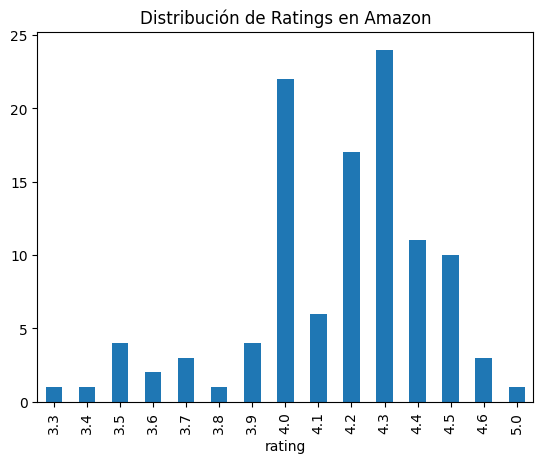

In [25]:
laptop_products["rating"].value_counts().sort_index().plot(kind='bar', title='Distribución de Ratings en Amazon')

In [26]:
laptop_products["sentiment"] = laptop_products["rating"].apply(map_amazon_sentiment)

In [ ]:
with open('LR_model.sav', 'rb') as f:
    data = pickle.load(f)

model = data['model']
vectorizer = data['vectorizer']

# Usar con reseñas de laptops
X_laptops = laptop_products['review_content']
X_vectorized = vectorizer.transform(X_laptops)
predictions = model.predict(X_vectorized)

In [27]:
y_test = laptop_products['sentiment']
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      Neutro       1.00      0.88      0.93        16
    Positivo       0.98      1.00      0.99        94

    accuracy                           0.98       110
   macro avg       0.99      0.94      0.96       110
weighted avg       0.98      0.98      0.98       110



In [31]:
# Mostrar los primeros diez productos de sentiment Positivo. Mostrar solamente product_name
positive_laptops = laptop_products[laptop_products['sentiment'] == 'Positivo']
positive_laptops[['product_name']].head(10)

,product_name
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
9,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
17,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
25,Tizum High Speed HDMI Cable with Ethernet | Su...
31,Ambrane 60W / 3A Type C Fast Charging Unbreaka...
43,TP-Link Nano AC600 USB Wi-Fi Adapter(Archer T2...
56,TP-LINK WiFi Dongle 300 Mbps Mini Wireless Net...
62,Lapster 1.5 mtr USB 2.0 Type A Male to USB A M...
63,AmazonBasics USB Type-C to USB Type-C 2.0 Cabl...
69,Amazon Basics USB Type-C to USB-A 2.0 Male Fas...


In [32]:
# Matriz de confusión
cm = confusion_matrix(y_test, predictions, labels=['Positivo', 'Neutro', 'Negativo'])
cm_df = pd.DataFrame(cm, index=['Positivo', 'Neutro', 'Negativo'], columns=['Positivo', 'Neutro', 'Negativo'])

<Axes: >

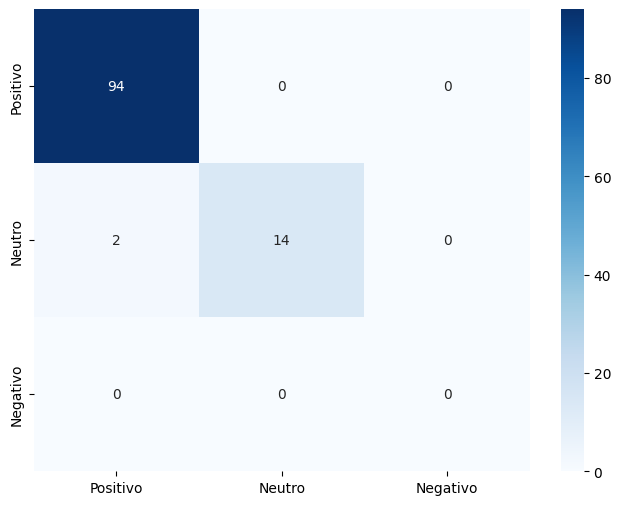

In [33]:
# Visualizar matriz de confusión
plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')